# 01 · Dataset Understanding & Exploration
**Chest X-Ray Classification with ResNet50 Transfer Learning (TensorFlow / Keras)**  
*Task 1* · MSc Data Science group project

**In this notebook**
- Kaggle chest X-ray dataset: 7,135 images in 4 classes (COVID-19, Normal, Pneumonia, Tuberculosis)
- Summary statistics per split and class imbalance (Pneumonia 3,875 vs COVID-19 460 in train)
- Image resolution and colour-mode audit
- Class distribution charts and sample X-rays for every class

> **How to use these notebooks.** The outputs below come from one complete run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (data generators, the trained model, predictions), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[Transfer Learning Model & Preprocessing →](02_transfer_learning_model.ipynb)

---

# Chest X-Ray Classification using Transfer Learning (ResNet50)
### Group Assignment — Exploring Transfer Learning for Image Classification

**Dataset:** Chest X-Ray — Pneumonia, COVID-19 & Tuberculosis (7,135 images)  
**Model:** ResNet50 (pre-trained on ImageNet) with a custom 512 → 256 → 128 → 4 head  
**Classes:** COVID-19 · Normal · Pneumonia · Tuberculosis  
**Framework:** TensorFlow / Keras  
**Result:** **92.35 % test accuracy** (weighted F1 0.923) on 771 held-out images; COVID-19 and Tuberculosis F1 = 1.00

---

## Task 1 — Dataset Understanding and Exploration

This section covers loading the dataset, exploring its structure, providing summary statistics, and visualising sample images to understand the characteristics of the data.

### 1.1 Install & Import Libraries

In [ ]:
import os, json, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from collections import Counter
from PIL import Image
warnings.filterwarnings('ignore')
print("✅ Libraries imported")


✅ Libraries imported


### 1.2 Dataset Download & Structure

We use the `jtiptj/chest-xray-pneumoniacovid19tuberculosis` dataset from Kaggle, which contains chest X-ray images across 4 classes: **COVID-19**, **Normal**, **Pneumonia**, and **Tuberculosis**. The dataset is pre-split into `train`, `val`, and `test` folders.

In [ ]:
import kagglehub

path = kagglehub.dataset_download("jtiptj/chest-xray-pneumoniacovid19tuberculosis")
data_dir = path
print("✅ Dataset ready!  Path:", data_dir)
print("📁 Contents:", os.listdir(data_dir))


✅ Dataset ready!  Path: /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis
📁 Contents: ['val', 'test', 'train']


In [ ]:
print("📁 Full folder tree:\n")
for root, dirs, files_list in os.walk(data_dir):
    level  = root.replace(data_dir, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}📁 {os.path.basename(root)}/")
    if level >= 2:
        print(f"{indent}  → {len(files_list)} images")


📁 Full folder tree:

📁 chest-xray-pneumoniacovid19tuberculosis/
  📁 val/
    📁 PNEUMONIA/
      → 8 images
    📁 NORMAL/
      → 8 images
    📁 COVID19/
      → 10 images
    📁 TURBERCULOSIS/
      → 12 images
  📁 test/
    📁 PNEUMONIA/
      → 390 images
    📁 NORMAL/
      → 234 images
    📁 COVID19/
      → 106 images
    📁 TURBERCULOSIS/
      → 41 images
  📁 train/
    📁 PNEUMONIA/
      → 3875 images
    📁 NORMAL/
      → 1341 images
    📁 COVID19/
      → 460 images
    📁 TURBERCULOSIS/
      → 650 images


### 1.3 Summary Statistics

We inspect the number of images per class across all splits to understand dataset size and class imbalance.

In [ ]:
splits      = ['train', 'val', 'test']
train_dir   = os.path.join(data_dir, 'train')
class_names = sorted(os.listdir(train_dir))
print(f"📌 Classes detected : {class_names}")
print(f"📌 Number of classes: {len(class_names)}\n")

summary = {}
for split in splits:
    split_dir = os.path.join(data_dir, split)
    if not os.path.exists(split_dir):
        continue
    summary[split] = {}
    for cls in class_names:
        cls_dir = os.path.join(split_dir, cls)
        if os.path.exists(cls_dir):
            count = len([f for f in os.listdir(cls_dir)
                         if f.lower().endswith(('.jpg','.jpeg','.png'))])
            summary[split][cls] = count

df_summary = pd.DataFrame(summary).fillna(0).astype(int)
df_summary['TOTAL'] = df_summary.sum(axis=1)
print("📊 Image Count per Class per Split:")
print(df_summary.to_string())
print(f"\n📌 Grand Total: {df_summary['TOTAL'].sum()}")


📌 Classes detected : ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']
📌 Number of classes: 4

📊 Image Count per Class per Split:
               train  val  test  TOTAL
COVID19          460   10   106    576
NORMAL          1341    8   234   1583
PNEUMONIA       3875    8   390   4273
TURBERCULOSIS    650   12    41    703

📌 Grand Total: 7135


### 1.4 Image Dimensions

Raw images vary in resolution and colour mode across classes. All images will be resized to **224×224** to match ResNet50's input requirements.

In [ ]:
print("📐 Sample image dimensions per class:\n")
dim_records = []
for cls in class_names:
    cls_dir = os.path.join(data_dir, 'train', cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))][:3]
    for fname in files:
        with Image.open(os.path.join(cls_dir, fname)) as img:
            w, h = img.size
            dim_records.append({'Class': cls, 'Width': w,
                                 'Height': h, 'Mode': img.mode})
df_dims = pd.DataFrame(dim_records)
print(df_dims.to_string(index=False))
print("\n📌 Images will be resized to 224×224 for ResNet50")


📐 Sample image dimensions per class:

        Class  Width  Height Mode
      COVID19   2000    2000    L
      COVID19   2000    2000    L
      COVID19    880     891  RGB
       NORMAL   1336    1128    L
       NORMAL   1400    1260    L
       NORMAL   1218    1032    L
    PNEUMONIA   1024     712    L
    PNEUMONIA   1424    1016    L
    PNEUMONIA   1376    1208    L
TURBERCULOSIS    512     512    L
TURBERCULOSIS    512     512    L
TURBERCULOSIS    512     512    L

📌 Images will be resized to 224×224 for ResNet50


### 1.5 Class Distribution Visualisation

The bar chart below shows the number of images per class in each split. Note the significant class imbalance — **Pneumonia dominates** the training set (3,875 images) while **COVID-19 is the minority class** (460 images). This imbalance is addressed later using class weights.

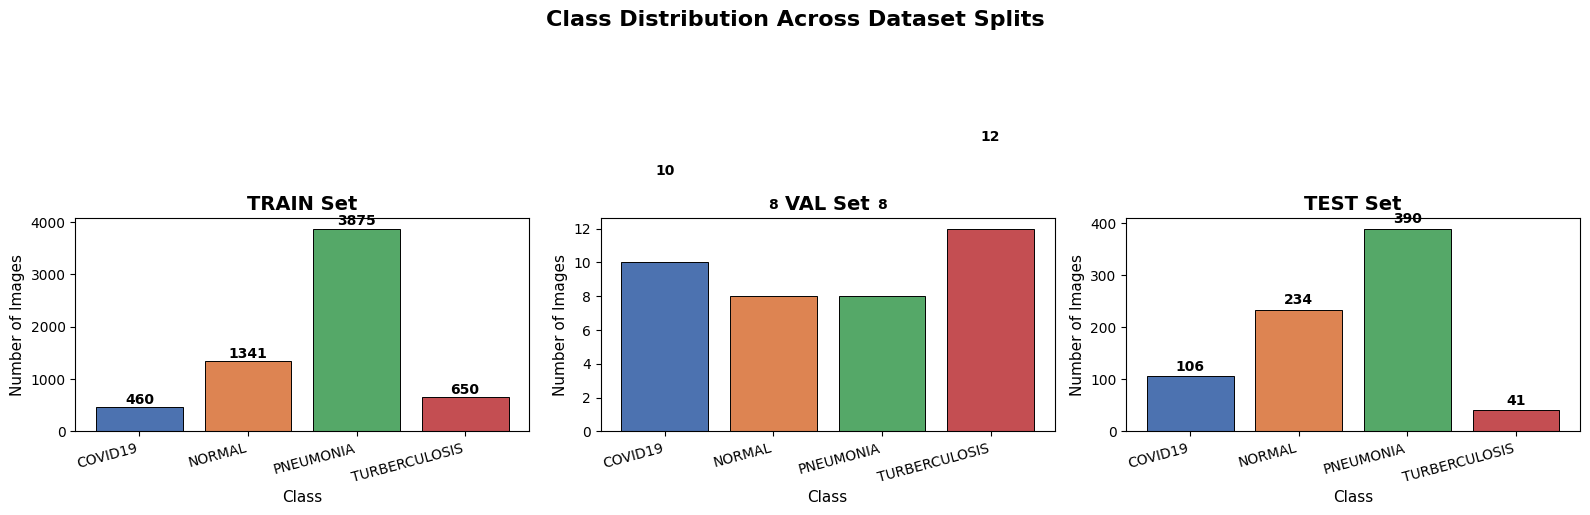

✅ Chart saved


In [ ]:
fig, axes = plt.subplots(1, len(summary), figsize=(17, 6))
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for ax, (split, counts) in zip(axes, summary.items()):
    bars = ax.bar(counts.keys(), counts.values(),
                  color=colors, edgecolor='black', linewidth=0.7)
    ax.set_title(f'{split.upper()} Set', fontsize=14, fontweight='bold')
    ax.set_xlabel('Class', fontsize=11)
    ax.set_ylabel('Number of Images', fontsize=11)
    ax.set_xticklabels(counts.keys(), rotation=15, ha='right')

    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(counts.values())*0.01,
                str(val),
                ha='center',
                va='bottom',
                fontsize=10,
                fontweight='bold')

plt.suptitle('Class Distribution Across Dataset Splits',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Chart saved")

### 1.6 Sample Image Visualisation

Five sample images are shown for each class to understand visual characteristics — texture, intensity, and patterns that distinguish each condition.

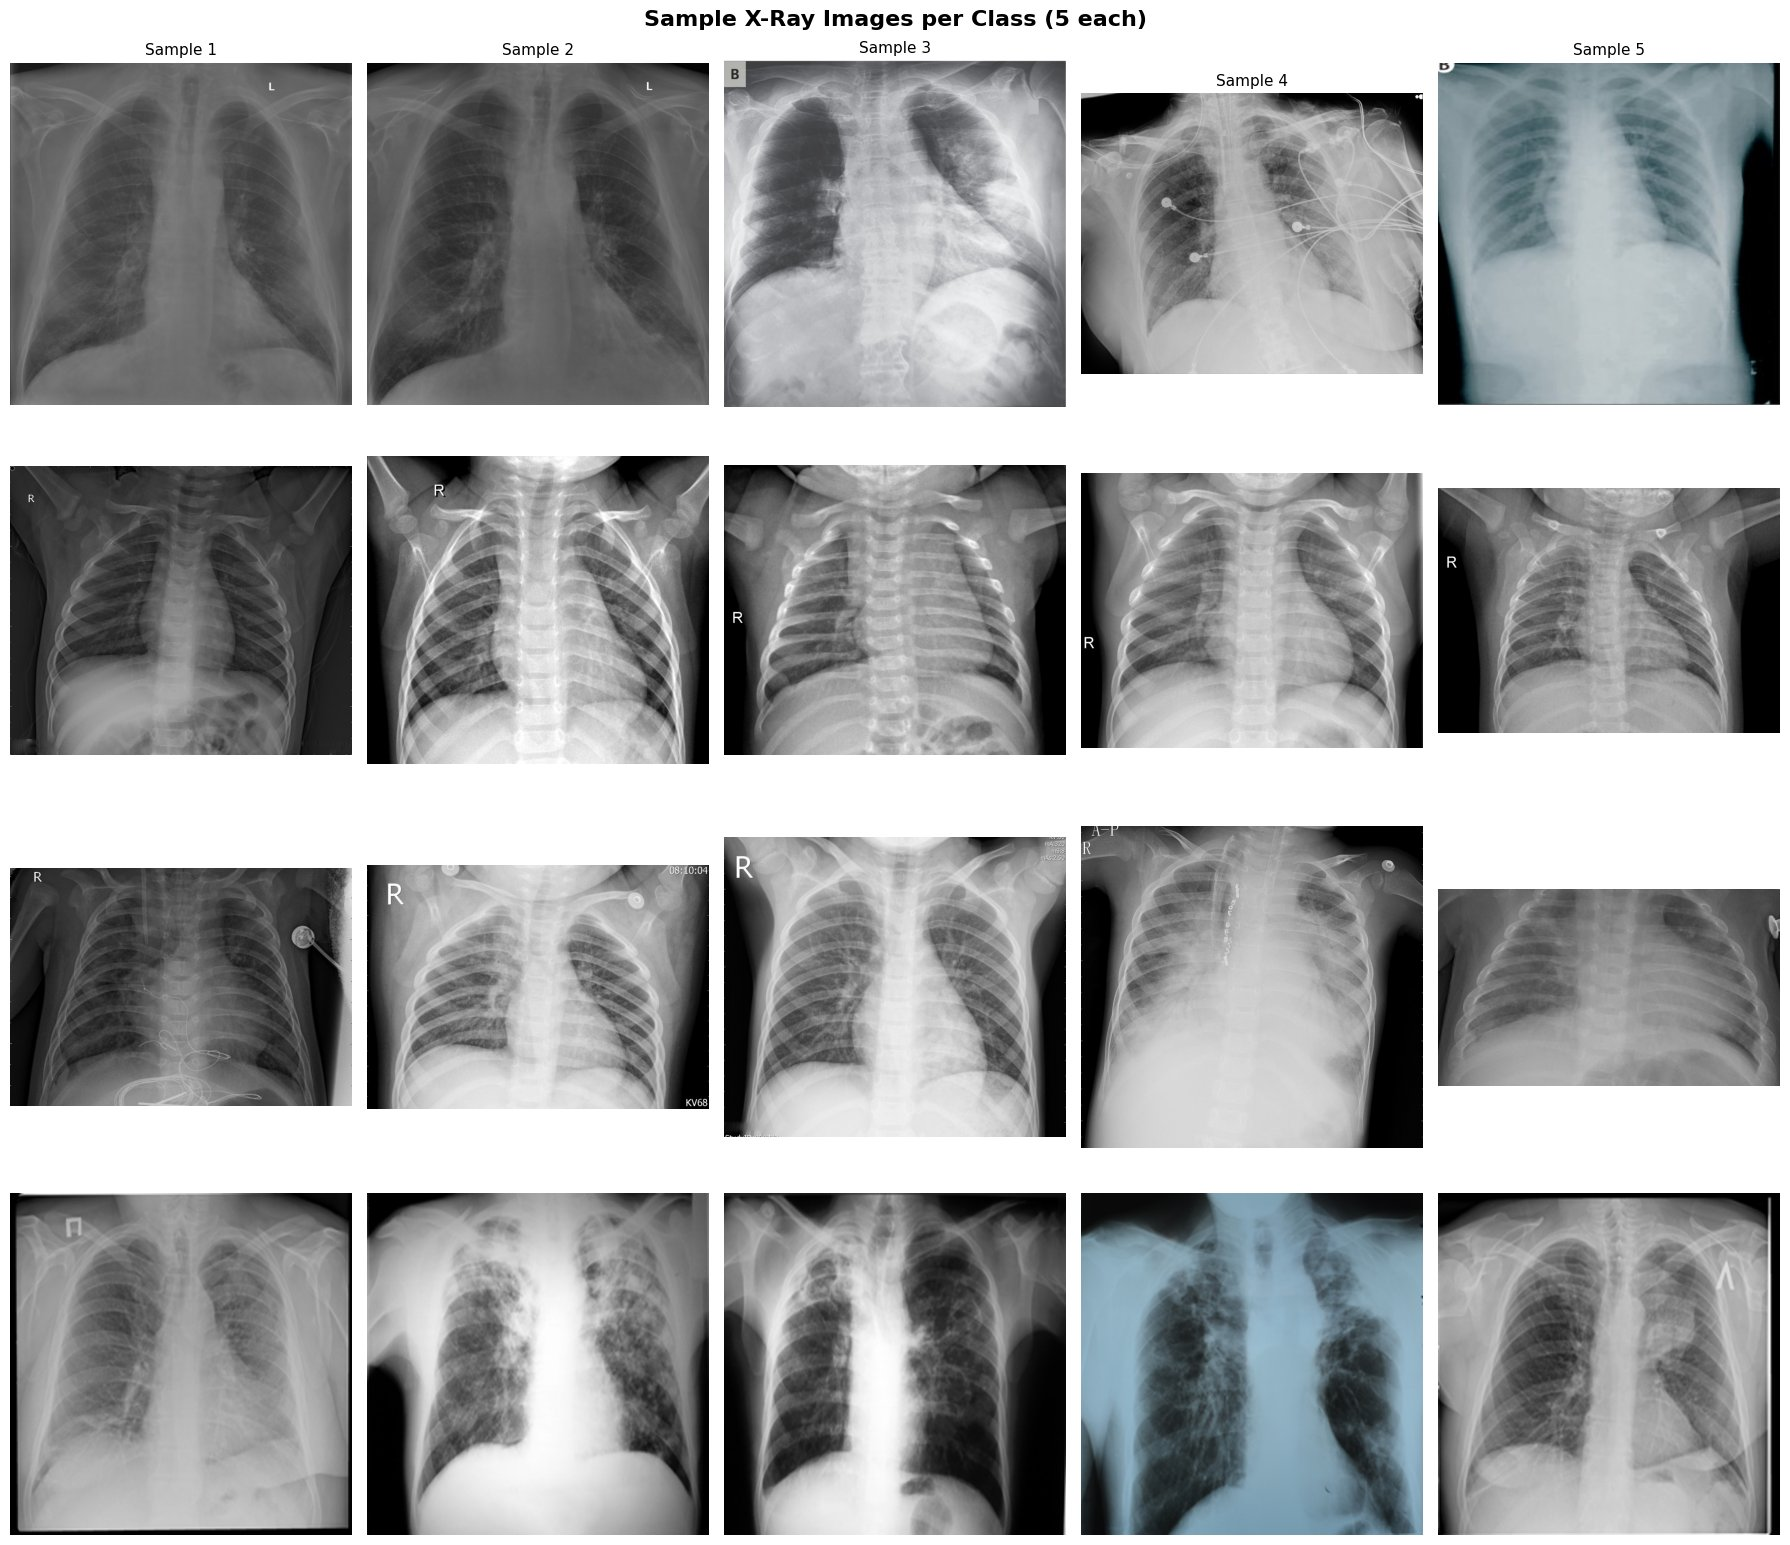

✅ Sample images saved


In [ ]:
fig, axes = plt.subplots(len(class_names), 5,
                          figsize=(18, 4*len(class_names)))
for row_idx, cls in enumerate(class_names):
    cls_dir = os.path.join(data_dir, 'train', cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))][:5]
    for col_idx, fname in enumerate(files):
        img = mpimg.imread(os.path.join(cls_dir, fname))
        axes[row_idx][col_idx].imshow(
            img, cmap='gray' if len(img.shape) == 2 else None)
        axes[row_idx][col_idx].axis('off')
        if col_idx == 0:
            axes[row_idx][col_idx].set_ylabel(
                cls, fontsize=13, fontweight='bold',
                rotation=90, labelpad=10, color='darkblue')
        if row_idx == 0:
            axes[row_idx][col_idx].set_title(f'Sample {col_idx+1}', fontsize=11)
plt.suptitle('Sample X-Ray Images per Class (5 each)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Sample images saved")


---

[Next: Transfer Learning Model & Preprocessing →](02_transfer_learning_model.ipynb)